In [50]:
import json
import urllib.request
import ssl
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc 
import anndata as ad
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Extraction

100.064 instances on h5ad files on CELLxGENE data which can be found here: https://cellxgene.cziscience.com/collections/65db5560-7aeb-4c66-b150-5bd914480eb8


The following code is based on section 2 Loading the data in the scvi_intro jupyter notebook

The cell below downloads the atlas from **CELLxGENE** (~850 MB) the first time and saves it as `data/wu2021_brca.h5ad`. Next time it just loads the file. If you prefer, you can also use the GEO version (GSE176078) by extracting it into `data/Wu_etal_2021_BRCA_scRNASeq/`.

scVI needs **raw counts**, so the code checks that the matrix contains whole numbers. It also renames the metadata columns to `patient`, `subtype`, `celltype` and `celltype_minor`.


In [13]:
DATA_DIR = Path("../../data")
H5AD_PATH = DATA_DIR / "wu_2021_breast_cancer.h5ad"
GEO_DIR = DATA_DIR / "geo_data"  # Backup source if CELLxGENE fails

CXG_COLLECTION_ID = "dea97145-f712-431c-a223-6b5f565f362a"
CXG_DATASET_ID    = "9fddb063-056d-4202-8b8a-4b0ee531d3ce"

# Set to None to keep the full dataset for EDA (skips subsampling)
N_CELLS = None 
SEED = 42

#  Helper Functions 
def to_dense(x):
    if sp.issparse(x):
        return x.toarray()
    if hasattr(x, "todense"):
        return np.asarray(x.todense())
    return np.asarray(x)

# We need raw counts as input to scVI and for scanpy functions
def is_integer_counts(X, n=500):
    sub = to_dense(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

def ssl_context():
    try:
        import certifi
        return ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        return ssl.create_default_context()

def download_from_cellxgene():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api_url = (f"https://api.cellxgene.cziscience.com/curation/v1/collections/"
               f"{CXG_COLLECTION_ID}/datasets/{CXG_DATASET_ID}")
    ctx = ssl_context()
    with urllib.request.urlopen(api_url, context=ctx) as r:
        meta = json.load(r)
    url = next((a["url"] for a in meta.get("assets", []) if a.get("filetype") == "H5AD"), None)
    if url is None:
        raise ValueError("No H5AD file found in the CELLxGENE dataset metadata.")

    print(f"Downloading {url} (~850 MB), this can take a while...")
    tmp_path = H5AD_PATH.with_suffix(".h5ad.part")
    with urllib.request.urlopen(url, context=ctx) as r, open(tmp_path, "wb") as f:
        shutil.copyfileobj(r, f, length=16 * 1024 * 1024)
    tmp_path.rename(H5AD_PATH)
    print("Download complete.")

def load_wu2021():
    if not H5AD_PATH.exists() and not GEO_DIR.exists():
        print("Data not found locally, downloading it from CELLxGENE.")
        try:
            download_from_cellxgene()
        except Exception as e:
            raise FileNotFoundError(f"Automatic download failed ({e}). Download manually to {H5AD_PATH}.") from e

    if H5AD_PATH.exists():
        adata = sc.read_h5ad(H5AD_PATH)
        if not is_integer_counts(adata.X):
            assert adata.raw is not None, "X is not raw counts and there is no .raw"
            adata = adata.raw.to_adata()
        
        if "feature_name" in adata.var: # CELLxGENE uses Ensembl IDs as the index
            adata.var["ensembl_id"] = adata.var_names
            adata.var_names = adata.var["feature_name"].astype(str)
            
    elif GEO_DIR.exists():
        X = sp.mmread(GEO_DIR / "count_matrix_sparse.mtx").tocsr()
        genes = pd.read_csv(GEO_DIR / "count_matrix_genes.tsv", header=None, sep="\t")[0].astype(str).values
        barcodes = pd.read_csv(GEO_DIR / "count_matrix_barcodes.tsv", header=None, sep="\t")[0].astype(str).values
        if X.shape[0] == len(genes) and X.shape[1] == len(barcodes):
            X = X.T.tocsr()
        meta = pd.read_csv(GEO_DIR / "metadata.csv", index_col=0)
        adata = ad.AnnData(X=X, obs=meta.loc[barcodes].copy(), var=pd.DataFrame(index=genes))
    else:
        raise FileNotFoundError("Data file not found.")

    adata.var_names_make_unique()
    assert is_integer_counts(adata.X), "The matrix doesn't look like raw counts"
    return adata

def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

# processing
adata = load_wu2021()

# Standardizing names 
COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}

for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")

# FPerforms subsample on the Data,a s we are currently 
if N_CELLS is not None and adata.n_obs > N_CELLS:
    sc.pp.subsample(adata, n_obs=N_CELLS, random_state=SEED)

print(f"Loaded: {adata.n_obs:,} cells × {adata.n_vars:,} genes | {adata.obs['patient'].nunique()} patients")

Data not found locally, downloading it from CELLxGENE.
Download complete.
Loaded: 100,064 cells × 28,523 genes | 26 patients


We have 26 different patients. 
From patients, we obtain a total of 100.064 individual cells.
Each of this individual cells contain the same amount of genes (20.000 - 30.000)

In our case, we have 100064 rows (cells) and 29067 columns (genes). Each cell inside the table is a numeric count showing how active a specific gene was inside a specific individual cell.

Current data is an AnnData object, not a regular DataFrame but rather a specialized data structure for single-cell genomics. 

It is split into several components, which will be analyzed below.

- adata.obs: Metadata for individual cells
- adata.var: Metadata for individual genes
- adata.obsm: 2D coordinates assigned to each cell for UMAP visualization
- adata.uns: Contains global metadata.
- adata.X : Obtains both cells and genes in one single matrix

In [14]:
print(adata)

AnnData object with n_obs × n_vars = 100064 × 28523
    obs: 'donor_id', 'percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_major', 'celltype_minor', 'celltype_subset', 'subtype', 'gene_module', 'calls', 'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed', 'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER', 'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67', 'subtype_by_IHC', 'treatment_status', 'treatment_details', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'disease_ontology_term_id', 'grade', 'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy', 'cell_type_ontology_term_id_legacy', 'celltype_major_legacy', 'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'patient', 'celltype'
    var: 'cellranger_symbol

## EDA

We will now analyze the different elements from the AnnData object to obtain initial insights

Firstly, we will analyze the document metadata.

In [ ]:
adata.uns

{'X_approximate_distribution': 'normal',
 'citation': 'Publication: https://doi.org/10.1038/s41588-021-00911-1 Dataset Version: https://datasets.cellxgene.cziscience.com/a9e2497a-0600-4bbd-8095-0e1271b10b1d.h5ad curated and distributed by CZ CELLxGENE Discover in Collection: https://cellxgene.cziscience.com/collections/dea97145-f712-431c-a223-6b5f565f362a',
 'is_pre_analysis': False,
 'organism': 'Homo sapiens',
 'organism_ontology_term_id': 'NCBITaxon:9606',
 'schema_reference': 'https://github.com/chanzuckerberg/single-cell-curation/blob/main/schema/7.1.0/schema.md',
 'schema_version': '7.1.0',
 'title': 'A single-cell and spatially-resolved atlas of human breast cancers'}

This returns basic information regarding the atlas which is not of much value to our analysis. The most important insight we can obtain here is from the X_approximate_distribution, which returns that the original file document was log-normalized. This is the reason data was fixed to ensure raw counts as it can be checked below.

In [17]:
print(adata.X.data[:10])

[1. 1. 1. 1. 1. 1. 2. 1. 1. 8.]


adata.obsm contains 3D and 2d coordinates for all the cells (100064) which will be used later for visualization purposes.

In [29]:
print(adata.obsm)
print(f"3D coordinates assigned to each cell: {adata.obsm["X_Three-D"]} \n")
print(f"2D coordinates assigned to each cell: {adata.obsm["X_umap"]}")

AxisArrays with keys: 'X_Three-D', 'X_umap'
3D coordinates assigned to each cell: [[-5.35295157  3.73556767 -9.33543924]
 [-4.56584315  3.92109834 -9.06959203]
 [-5.15104156  3.8592907  -9.11317018]
 ...
 [-0.39132883 -8.35068454 -4.81697277]
 [-0.42506899 -8.26384486 -4.81174282]
 [-0.7252466  -8.92389812 -4.65256837]] 

2D coordinates assigned to each cell: [[-7.98827505 -8.24125195]
 [-7.11264515 -8.12227726]
 [-7.50182724 -8.19417953]
 ...
 [ 1.00968659 11.09076881]
 [ 1.03276897 10.93484974]
 [ 0.45509583 11.49497414]]


## EDA obs

As mentioned before, this contains columns describing each individual cell. 

To start we will use the same plot as in the scvi_intro notebook, however, this dataframe contains all of cells, it is not a subsample as in the previous graph 

In [32]:
# Removing redundant columns (the ones we replaced their name when loading data for clearness (donor_id -> patient))
redundant_cols = ["donor_id", "celltype_major", "author_cell_type"]
adata.obs.drop(columns=[c for c in redundant_cols if c in adata.obs.columns], inplace=True)
print(adata.obs.columns)

Index(['percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_minor',
       'celltype_subset', 'subtype', 'gene_module', 'calls',
       'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed',
       'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER',
       'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67',
       'subtype_by_IHC', 'treatment_status', 'treatment_details',
       'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type',
       'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id',
       'is_primary_data', 'disease_ontology_term_id', 'grade',
       'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy',
       'cell_type_ontology_term_id_legacy', 'celltype_major_legacy',
       'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay',
       'disease', 'sex', 'tissue', 'self_reported_ethnicity',
       'development_stage', 'observation_joinid', 'patient', 'celltype'],
      dtype='str')

**Brief Explanation on the data covered**

HER2+, TNBC and ER+ are the three main clinical breast cancer subtypes in this dataset

A tumor is a mini-ecosystem of cells, it does not consist only on pure cancer cells. It is split in three main groups:

- Immune System -> T-cells, Myeloid Cells, B-cells and Plasma cells (help combat tumors, although a higher number of this does not mean more immunity)

- Epithelial Cells -> Cancer Epithelial (actual cancer cells growing out of control), Normal Epithelial Cells (Healthy cells)

- Stromal Cells -> CAFs, Endothelial Cells, PVL (neutral)

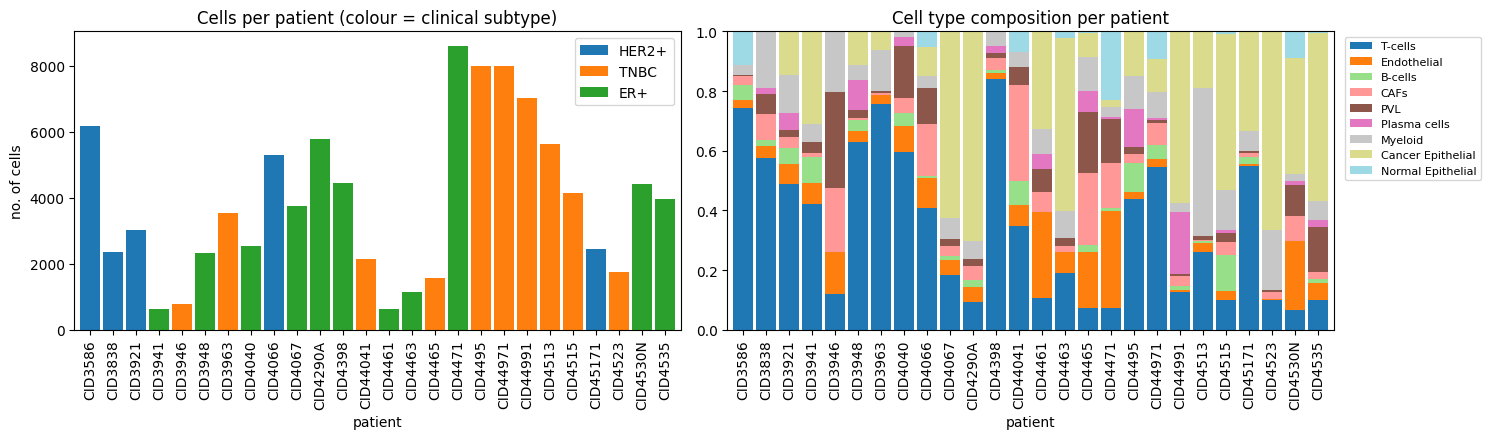

shape: (9, 3)
┌───────────────────┬───────┬────────────┐
│ celltype          ┆ count ┆ percentage │
│ ---               ┆ ---   ┆ ---        │
│ cat               ┆ u32   ┆ f64        │
╞═══════════════════╪═══════╪════════════╡
│ T-cells           ┆ 35214 ┆ 35.19      │
│ Cancer Epithelial ┆ 24489 ┆ 24.47      │
│ Myeloid           ┆ 9675  ┆ 9.67       │
│ Endothelial       ┆ 7605  ┆ 7.6        │
│ CAFs              ┆ 6573  ┆ 6.57       │
│ PVL               ┆ 5423  ┆ 5.42       │
│ Normal Epithelial ┆ 4355  ┆ 4.35       │
│ Plasma cells      ┆ 3524  ┆ 3.52       │
│ B-cells           ┆ 3206  ┆ 3.2        │
└───────────────────┴───────┴────────────┘


In [46]:
# Swtiching to polars as this is much faster when processing large data
obs_pl = pl.from_pandas(adata.obs, include_index=True)

# Cell counts per patient
counts_df = (
    obs_pl.group_by(["patient", "subtype"])
    .len(name="count")
    .pivot(on="subtype", index="patient", values="count")
    .fill_null(0)
    .sort("patient")
    .to_pandas()
    .set_index("patient")
)

# Cells per patient
comp_df = (
    obs_pl.group_by(["patient", "celltype"])
    .len(name="count")
    .with_columns((pl.col("count") / pl.col("count").sum().over("patient")).alias("prop"))
    .pivot(on="celltype", index="patient", values="prop")
    .fill_null(0)
    .sort("patient")
    .to_pandas()
    .set_index("patient")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

counts_df.plot.bar(stacked=True, ax=axes[0], width=0.85)
axes[0].set_title("Cells per patient (colour = clinical subtype)")
axes[0].set_ylabel("no. of cells")

comp_df.plot.bar(stacked=True, ax=axes[1], width=0.85, colormap="tab20", legend=False)
axes[1].set_title("Cell type composition per patient")
axes[1].legend(bbox_to_anchor=(1.01, 1), fontsize=8)

plt.tight_layout()
plt.show()

celltype_counts = (
    obs_pl.group_by("celltype")
    .len(name="count")
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100).round(2).alias("percentage")
    )
    .sort("count", descending=True)
)

print(celltype_counts)


Conclusions are fairly similar to those from the scvi intro

- 11 Patients have ER+, 10 Patients have TNBC, 5 patients have HER2+

- The number of cells varies a lot between patients. Some exceed a count of 8000 whereas others do not even reach 500 cells. This is something to take into account as some analysis may be skewed towards this patients. Thus some scaling or normalization may be applied.

- The most common cells are T-cells (~35%) followed closely by Cancer Epithelial Cells (~25%)

- Cell mix changes a lot between patients. Patients such as CID3586 or CID4398 have a high proportion of T-cells. On the other hand, patients such as CID4290A or CID4523 have a large amount of Cancer Epithelial cells


We will extend our analysis further with cell-level metrics, which allows to detect potential technical errors

- nCount_RNA: (Sequencing Depth) Measures the sum of all RNA molecules detected inside one single cell. High depth provides more information about the cell

- nFeature_RNA: Number of unique genes per cell. If it expresses a low number of genes, it is low quality

- percent_mito: Percentage of a cell`s total RNA coming from mitochondria. Dying cells usually have a spike in this percentage, we will make sure they are not above 15%.



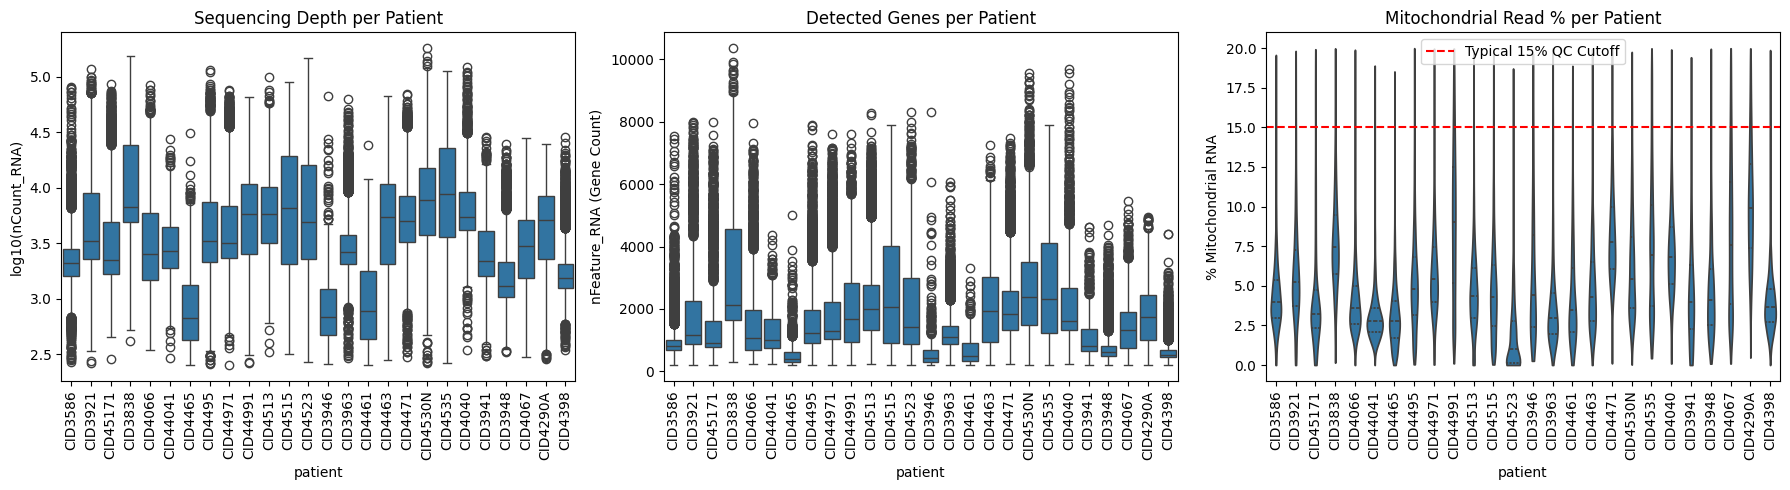

Rows: 26
Columns: 5
$ patient       <cat> CID3586, CID3838, CID3921, CID3941, CID3946, CID3948, CID3963, CID4040, CID4066, CID4067
$ total_cells   <u32> 6178, 2353, 3024, 631, 774, 2327, 3527, 2531, 5309, 3764
$ median_counts <f64> 2088.5, 6741.0, 3301.0, 2199.0, 682.0, 1309.0, 2654.0, 5505.0, 2532.0, 3011.0
$ median_genes  <f64> 823.5, 2131.0, 1156.5, 823.0, 421.0, 602.0, 1093.0, 1627.0, 1069.0, 1329.5
$ mean_mito_pct <f32> 4.369999885559082, 7.829999923706055, 5.920000076293945, 5.070000171661377, 5.78000020980835, 4.739999771118164, 3.9000000953674316, 7.139999866485596, 4.21999979019165, 8.069999694824219



In [59]:
# Add log10 sequencing depth for clear visualization
obs_pl = obs_pl.with_columns(
    pl.col("nCount_RNA").log10().alias("log10_counts")
)

# Set up a 2x2 subplot grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

obs_pd = obs_pl.select(["patient", "log10_counts", "nFeature_RNA", "percent_mito", "celltype", "subtype"]).to_pandas()

# nCount_RNA
sns.boxplot(data=obs_pd, x="patient", y="log10_counts", ax=axes[0])
axes[0].set_title("Sequencing Depth per Patient")
axes[0].set_ylabel("log10(nCount_RNA)")
axes[0].tick_params(axis='x', rotation=90)

# nFeature_RNA
sns.boxplot(data=obs_pd, x="patient", y="nFeature_RNA", ax=axes[1])
axes[1].set_title("Detected Genes per Patient")
axes[1].set_ylabel("nFeature_RNA (Gene Count)")
axes[1].tick_params(axis='x', rotation=90)

#  Percent Mitochondrial Reads per Patient 
sns.violinplot(data=obs_pd, x="patient", y="percent_mito", ax=axes[2], cut=0, inner="quartile")
axes[2].axhline(15, color="red", linestyle="--", label="Typical 15% QC Cutoff")
axes[2].set_title("Mitochondrial Read % per Patient")
axes[2].set_ylabel("% Mitochondrial RNA")
axes[2].tick_params(axis='x', rotation=90)
axes[2].legend()

plt.tight_layout()
plt.show()

#Sumary Table of Patient and Metrics
patient_qc = (
    obs_pl.group_by("patient")
    .agg([
        pl.len().alias("total_cells"),
        pl.col("nCount_RNA").median().alias("median_counts"),
        pl.col("nFeature_RNA").median().alias("median_genes"),
        pl.col("percent_mito").mean().round(2).alias("mean_mito_pct")
    ])
    .sort("patient")
)

patient_qc.glimpse()

From the left plot:

- Median count vary by over x13 across patients. (scale is log normalized)

- Standard PCA does not fully capture difference between sequencing depth from biological variance.

- scVI solves this introducing the library size variable.

From the middle plot:

- Some patients have median gene counts under 500 unique genes per cell whereas others reach above 4000.

- Direct relation with the previous plot, when a cell is sequenced more deeply, more genes are detected

From the right plot:

- Across all patients, the percentages remain pretty low

- Damaged cells were already filtered out as it can be read in S.Z. Wu et al., “A single-cell and spatially resolved atlas of human breast cancers”, Nature Genetics
53:1334–1347, 2021. (Dataset.)

- High values mean usually damaged cells that lead to 0 counts. As this values are consistently low, it is more probable that a Zero-Inflated Negative Binomial Likelihood is not as needed as there wont be an extreme zero-inflation from dead cells (should be further analyzed)

From the table:

- A difference of 13x in magnitude in median between patients and x200 in median


## EDA var